In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("spy_us_d.csv")

In [3]:
df.head()

,Date,Open,High,Low,Close,Volume
0,1/4/2010,86.7050,87.4819,86.0150,87.4353,154164947
1,1/5/2010,87.3929,87.6975,87.0771,87.6670,144619532
2,1/6/2010,87.5854,87.9358,87.5089,87.7137,150444938
3,1/7/2010,87.5712,88.2019,87.3358,88.1023,169908131
4,1/8/2010,87.8564,88.4334,87.6859,88.3952,163831612


In [4]:
df["Date"] = pd.to_datetime(df["Date"])

In [5]:
df.head()

,Date,Open,High,Low,Close,Volume
0,2010-01-04,86.7050,87.4819,86.0150,87.4353,154164947
1,2010-01-05,87.3929,87.6975,87.0771,87.6670,144619532
2,2010-01-06,87.5854,87.9358,87.5089,87.7137,150444938
3,2010-01-07,87.5712,88.2019,87.3358,88.1023,169908131
4,2010-01-08,87.8564,88.4334,87.6859,88.3952,163831612


In [6]:
# Dataset info
print("Total rows:", len(df))
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

Total rows: 4023
First date: 2010-01-04 00:00:00
Last date: 2025-12-31 00:00:00


In [7]:
# check missing values
print(df.isnull().sum())

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [8]:
# check duplicated date
print("\nDuplicate dates:", df["Date"].duplicated().sum())
# Check completely identical rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate dates: 0
Duplicate rows: 0


In [9]:
# Data types
print("\nData types:")
print(df.dtypes)


Data types:
Date      datetime64[us]
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object


### Technical Indicators

In [10]:
# 1. Daily Return
df["Daily_Return"] = df["Close"].pct_change()

# 2. Five-Day Return (Momentum)
df["Return_5D"] = df["Close"].pct_change(periods=5)

# 3. Twenty-Day Moving Average
df["MA20"] = df["Close"].rolling(window=20).mean()

# 4. Twenty-Day Volatility
df["Volatility_20D"] = df["Daily_Return"].rolling(window=20).std()

# 5. Daily Volume Change
df["Volume_Change"] = df["Volume"].pct_change()

# 6. Price Relative to Moving Average
df["Price_to_MA20"] = df["Close"] / df["MA20"]

# 7. Next Trading Day's Date and Return
df["Target_Date"] = df["Date"].shift(-1)

df["Next_Day_Return"] = (
    df["Close"].shift(-1) / df["Close"] - 1
)

# 8. Next-Day Direction (1 = UP, 0 = NOT UP)
df["Next_Day_Direction"] = np.where(
    df["Next_Day_Return"].isna(),
    np.nan,
    (df["Next_Day_Return"] > 0).astype(int)
)

# Display results
df[[
    "Date", "Close", "Daily_Return",
    "Return_5D", "MA20", "Volatility_20D",
    "Volume_Change", "Price_to_MA20",
    "Next_Day_Return", "Next_Day_Direction"
]].tail(10)

,Date,Close,Daily_Return,Return_5D,MA20,Volatility_20D,Volume_Change,Price_to_MA20,Next_Day_Return,Next_Day_Direction
4013,2025-12-17,671.40,-0.011004,-0.023518,677.6475,0.007468,-0.093464,0.990781,0.007551,1.0
4014,2025-12-18,676.47,0.007551,-0.018428,678.3395,0.007590,-0.017854,0.997244,0.006090,1.0
4015,2025-12-19,680.59,0.006090,-0.001716,679.7425,0.006615,-0.046485,1.001247,0.006230,1.0
4016,2025-12-22,684.83,0.006230,0.006023,681.0325,0.006432,-0.328600,1.005576,0.004570,1.0
4017,2025-12-23,687.96,0.004570,0.013390,681.9940,0.005734,-0.067812,1.008748,0.003518,1.0
4018,2025-12-24,690.38,0.003518,0.028269,682.7620,0.005447,-0.391647,1.011158,-0.000101,0.0
4019,2025-12-26,690.31,-0.000101,0.020459,683.2935,0.005279,0.054956,1.010269,-0.003564,0.0
4020,2025-12-29,687.85,-0.003564,0.010667,683.5165,0.005245,0.503352,1.006340,-0.001221,0.0
4021,2025-12-30,687.01,-0.001221,0.003183,683.8535,0.005132,-0.246147,1.004616,-0.007409,0.0
4022,2025-12-31,681.92,-0.007409,-0.008780,683.8730,0.005414,0.572174,0.997144,NaN,NaN


## Filter the Dataset and Split the Data
###  The goal is to Keep the 2015–2025 observations and divide them into training, validation, and testing periods.

In [11]:
# Keep observations from 2015 to 2025
model_df = df[
    (df["Date"] >= "2015-01-01") &
    (df["Date"] <= "2025-12-31")
].copy()

# Remove rows with missing required values
required_columns = [
    "Daily_Return",
    "Return_5D",
    "Volatility_20D",
    "Volume_Change",
    "Price_to_MA20",
    "Target_Date",
    "Next_Day_Direction"
]

model_df = model_df.dropna(subset=required_columns)

# Split by the date of the next-day outcome
model_df["Split"] = np.select(
    [
        model_df["Target_Date"].dt.year <= 2022,
        model_df["Target_Date"].dt.year == 2023,
        model_df["Target_Date"].dt.year.between(2024, 2025)
    ],
    ["Train", "Validation", "Test"],
    default="Exclude"
)

model_df = model_df[model_df["Split"] != "Exclude"].copy()

# Results
print("Total observations:", len(model_df))
print("\nObservations by period:")
print(model_df["Split"].value_counts())

model_df[[
    "Date", "Daily_Return", "Return_5D",
    "Volatility_20D", "Next_Day_Direction", "Split"
]].head()

Total observations: 2765

Observations by period:
Split
Train         2013
Test           502
Validation     250
Name: count, dtype: int64


,Date,Daily_Return,Return_5D,Volatility_20D,Next_Day_Direction,Split
1257,2015-01-02,-0.000598,-0.011433,0.010012,0.0,Train
1258,2015-01-05,-0.018086,-0.032126,0.010778,0.0,Train
1259,2015-01-06,-0.009346,-0.042274,0.010907,1.0,Train
1260,2015-01-07,0.012290,-0.025709,0.011270,1.0,Train
1261,2015-01-08,0.017907,0.001725,0.012016,0.0,Train


## Convert Numerical Data into Categories
### Apriori Association Rules

In [12]:
# Use training data to calculate thresholds
train_df = model_df[model_df["Split"] == "Train"]

# Median of 20-day volatility
vol_threshold = train_df["Volatility_20D"].median()

# 25th and 75th percentiles of 5-day returns
mom_low = train_df["Return_5D"].quantile(0.25)
mom_high = train_df["Return_5D"].quantile(0.75)

print(f"Volatility threshold: {vol_threshold:.3%}")
print(f"Weak momentum threshold: {mom_low:.3%}")
print(f"Strong momentum threshold: {mom_high:.3%}")

Volatility threshold: 0.786%
Weak momentum threshold: -0.719%
Strong momentum threshold: 1.445%


In [13]:
# 1. Today's return
model_df["Return_Category"] = np.where(
    model_df["Daily_Return"] > 0,
    "Return_Positive",
    "Return_Nonpositive"
)

# 2. Market volatility
model_df["Volatility_Category"] = np.where(
    model_df["Volatility_20D"] > vol_threshold,
    "Volatility_High",
    "Volatility_Low"
)

# 3. Trading volume
model_df["Volume_Category"] = np.where(
    model_df["Volume_Change"] > 0,
    "Volume_Increase",
    "Volume_No_Increase"
)

# 4. Closing price relative to MA20
model_df["MA20_Category"] = np.where(
    model_df["Price_to_MA20"] > 1,
    "Above_MA20",
    "At_or_Below_MA20"
)

# 5. Five-day momentum
model_df["Momentum_Category"] = np.select(
    [
        model_df["Return_5D"] > mom_high,
        model_df["Return_5D"] < mom_low
    ],
    [
        "Strong_5D_Momentum",
        "Weak_5D_Momentum"
    ],
    default="Neutral_5D_Momentum"
)

# 6. Actual next-day direction
model_df["Next_Day_Category"] = np.where(
    model_df["Next_Day_Direction"] == 1,
    "Next_Day_UP",
    "Next_Day_NOT_UP"
)

# Display the categorical dataset
category_cols = [
    "Date", "Return_Category",
    "Volatility_Category", "Volume_Category",
    "MA20_Category", "Momentum_Category",
    "Next_Day_Category", "Split"
]

model_df[category_cols].head(10)

,Date,Return_Category,Volatility_Category,Volume_Category,MA20_Category,Momentum_Category,Next_Day_Category,Split
1257,2015-01-02,Return_Nonpositive,Volatility_High,Volume_No_Increase,Above_MA20,Weak_5D_Momentum,Next_Day_NOT_UP,Train
1258,2015-01-05,Return_Nonpositive,Volatility_High,Volume_Increase,At_or_Below_MA20,Weak_5D_Momentum,Next_Day_NOT_UP,Train
1259,2015-01-06,Return_Nonpositive,Volatility_High,Volume_Increase,At_or_Below_MA20,Weak_5D_Momentum,Next_Day_UP,Train
1260,2015-01-07,Return_Positive,Volatility_High,Volume_No_Increase,At_or_Below_MA20,Weak_5D_Momentum,Next_Day_UP,Train
1261,2015-01-08,Return_Positive,Volatility_High,Volume_Increase,Above_MA20,Neutral_5D_Momentum,Next_Day_NOT_UP,Train
1262,2015-01-09,Return_Nonpositive,Volatility_High,Volume_Increase,Above_MA20,Neutral_5D_Momentum,Next_Day_NOT_UP,Train
1263,2015-01-12,Return_Nonpositive,Volatility_High,Volume_No_Increase,At_or_Below_MA20,Neutral_5D_Momentum,Next_Day_NOT_UP,Train
1264,2015-01-13,Return_Nonpositive,Volatility_High,Volume_Increase,At_or_Below_MA20,Neutral_5D_Momentum,Next_Day_NOT_UP,Train
1265,2015-01-14,Return_Nonpositive,Volatility_High,Volume_No_Increase,At_or_Below_MA20,Neutral_5D_Momentum,Next_Day_NOT_UP,Train
1266,2015-01-15,Return_Nonpositive,Volatility_High,Volume_No_Increase,At_or_Below_MA20,Weak_5D_Momentum,Next_Day_UP,Train


In [15]:
# Check each category's frequency
for col in category_cols[1:-1]:
    print(f"\n{col}")
    print(model_df[col].value_counts())

print("\nMissing categories:")
print(model_df[category_cols].isna().sum())


Return_Category
Return_Category
Return_Positive       1516
Return_Nonpositive    1249
Name: count, dtype: int64

Volatility_Category
Volatility_Category
Volatility_Low     1400
Volatility_High    1365
Name: count, dtype: int64

Volume_Category
Volume_Category
Volume_No_Increase    1400
Volume_Increase       1365
Name: count, dtype: int64

MA20_Category
MA20_Category
Above_MA20          1891
At_or_Below_MA20     874
Name: count, dtype: int64

Momentum_Category
Momentum_Category
Neutral_5D_Momentum    1378
Strong_5D_Momentum      709
Weak_5D_Momentum        678
Name: count, dtype: int64

Next_Day_Category
Next_Day_Category
Next_Day_UP        1516
Next_Day_NOT_UP    1249
Name: count, dtype: int64

Missing categories:
Date                   0
Return_Category        0
Volatility_Category    0
Volume_Category        0
MA20_Category          0
Momentum_Category      0
Next_Day_Category      0
Split                  0
dtype: int64


In [16]:
cat_columns = [
    "Return_Category",
    "Volatility_Category",
    "Volume_Category",
    "MA20_Category",
    "Momentum_Category",
    "Next_Day_Category"
]

# Convert categories into True/False columns
transactions = pd.get_dummies(
    model_df[cat_columns],
    dtype=bool
)

transactions.head()

,Return_Category_Return_Nonpositive,Return_Category_Return_Positive,Volatility_Category_Volatility_High,Volatility_Category_Volatility_Low,Volume_Category_Volume_Increase,Volume_Category_Volume_No_Increase,MA20_Category_Above_MA20,MA20_Category_At_or_Below_MA20,Momentum_Category_Neutral_5D_Momentum,Momentum_Category_Strong_5D_Momentum,Momentum_Category_Weak_5D_Momentum,Next_Day_Category_Next_Day_NOT_UP,Next_Day_Category_Next_Day_UP
1257,True,False,True,False,False,True,True,False,False,False,True,True,False
1258,True,False,True,False,True,False,False,True,False,False,True,True,False
1259,True,False,True,False,True,False,False,True,False,False,True,False,True
1260,False,True,True,False,False,True,False,True,False,False,True,False,True
1261,False,True,True,False,True,False,True,False,True,False,False,True,False


## Apriori Association Rules

In [17]:
%pip install mlxtend

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.4 MB 2.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 4.3 MB/s  0:00:00
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------ --------------------------------- 1.3/8.4 MB 5.7 MB/s eta 0:00:02
   --------------- ------------------------ 3.1/8.4 MB 8.4 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.4 MB 12.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 12.8 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -------------- ------------------------- 13.1/37.4 MB 62.0 MB/s eta 0:00:01
   ------------------------ --------------- 2


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from mlxtend.frequent_patterns import apriori

# Select training observations
train_transactions = transactions.loc[
    model_df["Split"] == "Train"
].copy()

# Run Apriori
frequent_itemsets = apriori(
    train_transactions,
    min_support=0.05,
    use_colnames=True,
    max_len=4
)

# Sort by highest support
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

print("Number of frequent itemsets:", len(frequent_itemsets))

frequent_itemsets.head(15)


Number of frequent itemsets: 367


,support,itemsets
6,0.666667,frozenset({MA20_Category_Above_MA20})
12,0.538997,frozenset({Next_Day_Category_Next_Day_UP})
1,0.538997,frozenset({Return_Category_Return_Positive})
5,0.503229,frozenset({Volume_Category_Volume_No_Increase})
3,0.500248,frozenset({Volatility_Category_Volatility_Low})
8,0.500248,frozenset({Momentum_Category_Neutral_5D_Moment...
2,0.499752,frozenset({Volatility_Category_Volatility_High})
4,0.496771,frozenset({Volume_Category_Volume_Increase})
11,0.461003,frozenset({Next_Day_Category_Next_Day_NOT_UP})
0,0.461003,frozenset({Return_Category_Return_Nonpositive})


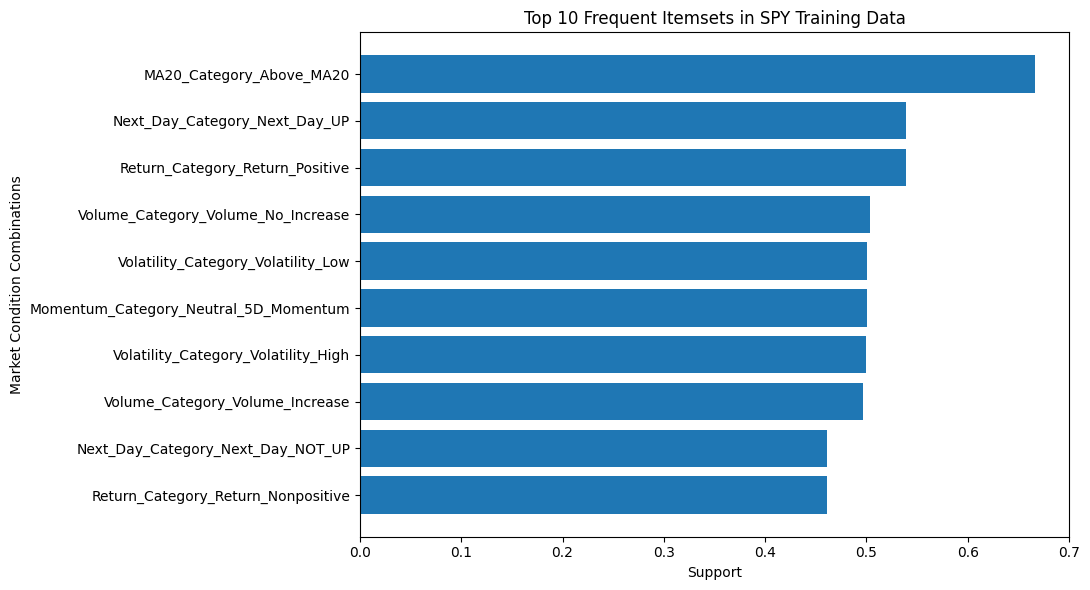

In [19]:
#10 most frequent itemsets
top10 = frequent_itemsets.head(10).copy()

# Convert itemsets into readable labels
top10["Itemset_Label"] = top10["itemsets"].apply(
    lambda x: " + ".join(sorted(x))
)

plt.figure(figsize=(11, 6))

plt.barh(
    top10["Itemset_Label"],
    top10["support"]
)

plt.xlabel("Support")
plt.ylabel("Market Condition Combinations")
plt.title("Top 10 Frequent Itemsets in SPY Training Data")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Generate Association Rules

In [20]:
from mlxtend.frequent_patterns import association_rules

# Generate rules from frequent itemsets
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.50,
    num_itemsets=len(train_transactions)
)

print("Total rules generated:", len(rules))

rules.head(10)

Total rules generated: 727


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({MA20_Category_Above_MA20}),frozenset({Return_Category_Return_Positive}),0.666667,0.538997,0.411823,0.617735,1.146083,1.0,0.052492,1.205978,0.382388,0.518773,0.170797,0.690895
1,frozenset({Return_Category_Return_Positive}),frozenset({MA20_Category_Above_MA20}),0.538997,0.666667,0.411823,0.764055,1.146083,1.0,0.052492,1.412760,0.276490,0.518773,0.292166,0.690895
2,frozenset({Momentum_Category_Neutral_5D_Moment...,frozenset({MA20_Category_Above_MA20}),0.500248,0.666667,0.400894,0.801390,1.202085,1.0,0.067395,1.678333,0.336392,0.523346,0.404171,0.701366
3,frozenset({MA20_Category_Above_MA20}),frozenset({Momentum_Category_Neutral_5D_Moment...,0.666667,0.500248,0.400894,0.601341,1.202085,1.0,0.067395,1.253583,0.504337,0.523346,0.202286,0.701366
4,frozenset({MA20_Category_Above_MA20}),frozenset({Volatility_Category_Volatility_Low}),0.666667,0.500248,0.399901,0.599851,1.199106,1.0,0.066402,1.248914,0.498137,0.521373,0.199304,0.699628
5,frozenset({Volatility_Category_Volatility_Low}),frozenset({MA20_Category_Above_MA20}),0.500248,0.666667,0.399901,0.799404,1.199106,1.0,0.066402,1.661716,0.332256,0.521373,0.398213,0.699628
6,frozenset({MA20_Category_Above_MA20}),frozenset({Next_Day_Category_Next_Day_UP}),0.666667,0.538997,0.356185,0.534277,0.991244,1.0,-0.003146,0.989867,-0.025815,0.419298,-0.010237,0.597553
7,frozenset({Next_Day_Category_Next_Day_UP}),frozenset({MA20_Category_Above_MA20}),0.538997,0.666667,0.356185,0.660829,0.991244,1.0,-0.003146,0.982790,-0.018800,0.419298,-0.017512,0.597553
8,frozenset({MA20_Category_Above_MA20}),frozenset({Volume_Category_Volume_No_Increase}),0.666667,0.503229,0.342275,0.513413,1.020237,1.0,0.006789,1.020929,0.059507,0.413565,0.020500,0.596785
9,frozenset({Volume_Category_Volume_No_Increase}),frozenset({MA20_Category_Above_MA20}),0.503229,0.666667,0.342275,0.680158,1.020237,1.0,0.006789,1.042181,0.039929,0.413565,0.040474,0.596785


In [21]:
# Define the two allowed outcomes
targets = {
    "Next_Day_Category_Next_Day_UP",
    "Next_Day_Category_Next_Day_NOT_UP"
}

# Keep next-day outcomes on the right side 
target_rules = rules[
    rules["consequents"].apply(
        lambda x: len(x) == 1 and bool(x & targets)
    )
    &
    rules["antecedents"].apply(
        lambda x: len(x & targets) == 0
    )
].copy()

print("Rules involving next-day direction:", len(target_rules))

Rules involving next-day direction: 103


In [22]:
# Convert into readable text
target_rules["Conditions"] = target_rules["antecedents"].apply(
    lambda x: " + ".join(
        sorted(item.split("_Category_")[-1] for item in x)
    )
)

target_rules["Outcome"] = target_rules["consequents"].apply(
    lambda x: next(iter(x)).split("_Category_")[-1]
)

# Sort by lift
target_rules = target_rules.sort_values(
    by=["lift", "support"],
    ascending=[False, False]
)

# Display 
target_rules[[
    "Conditions",
    "Outcome",
    "support",
    "confidence",
    "lift"
]].head(15)

,Conditions,Outcome,support,confidence,lift
672,Above_MA20 + Neutral_5D_Momentum + Volatility_...,Next_Day_NOT_UP,0.056135,0.538095,1.167226
453,Above_MA20 + Return_Positive + Volatility_High,Next_Day_NOT_UP,0.085445,0.522796,1.134040
471,Neutral_5D_Momentum + Return_Positive + Volume...,Next_Day_NOT_UP,0.083954,0.512121,1.110884
674,Return_Positive + Strong_5D_Momentum + Volatil...,Next_Day_NOT_UP,0.056135,0.511312,1.109129
531,Return_Nonpositive + Volatility_Low + Volume_I...,Next_Day_UP,0.077496,0.590909,1.096313
516,Neutral_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.079980,0.503125,1.091369
639,Above_MA20 + Volatility_High + Volume_Increase,Next_Day_NOT_UP,0.062593,0.501992,1.088912
249,Return_Positive + Volatility_High,Next_Day_NOT_UP,0.128664,0.501938,1.088794
501,Return_Positive + Volatility_High + Volume_No_...,Next_Day_NOT_UP,0.081470,0.500000,1.084591
666,At_or_Below_MA20 + Volatility_Low,Next_Day_UP,0.058619,0.584158,1.083789


## Evaluate Support, Confidence, and Lift

In [23]:
# Keep rules with sufficient support and lift
candidate_rules = target_rules[
    (target_rules["support"] >= 0.05) &
    (target_rules["lift"] > 1.0)
].copy()

candidate_rules = candidate_rules.sort_values(
    by="lift",
    ascending=False
)

# Display
pd.set_option("display.max_colwidth", None)

print("Candidate rules:", len(candidate_rules))

display(candidate_rules[[
    "Conditions",
    "Outcome",
    "support",
    "confidence",
    "lift"
]].head(10).round(4))

Candidate rules: 61


,Conditions,Outcome,support,confidence,lift
672,Above_MA20 + Neutral_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.0561,0.5381,1.1672
453,Above_MA20 + Return_Positive + Volatility_High,Next_Day_NOT_UP,0.0854,0.5228,1.1340
471,Neutral_5D_Momentum + Return_Positive + Volume_No_Increase,Next_Day_NOT_UP,0.0840,0.5121,1.1109
674,Return_Positive + Strong_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.0561,0.5113,1.1091
531,Return_Nonpositive + Volatility_Low + Volume_Increase,Next_Day_UP,0.0775,0.5909,1.0963
516,Neutral_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.0800,0.5031,1.0914
639,Above_MA20 + Volatility_High + Volume_Increase,Next_Day_NOT_UP,0.0626,0.5020,1.0889
249,Return_Positive + Volatility_High,Next_Day_NOT_UP,0.1287,0.5019,1.0888
501,Return_Positive + Volatility_High + Volume_No_Increase,Next_Day_NOT_UP,0.0815,0.5000,1.0846
666,At_or_Below_MA20 + Volatility_Low,Next_Day_UP,0.0586,0.5842,1.0838


## Calculate the normal next-day UP/DOWN frequency

In [24]:
# Calculate baseline outcomes in training data
up_rate = train_transactions[
    "Next_Day_Category_Next_Day_UP"
].mean()

not_up_rate = train_transactions[
    "Next_Day_Category_Next_Day_NOT_UP"
].mean()

print(f"Baseline UP rate: {up_rate:.2%}")
print(f"Baseline NOT UP rate: {not_up_rate:.2%}")

Baseline UP rate: 53.90%
Baseline NOT UP rate: 46.10%


### Validate Association Rules Using 2023 Data
    Do those same rules still show meaningful relationships in 2023, or did they only work in the training period?

In [26]:
# Select 2023 validation transactions
validation_transactions = transactions.loc[
    model_df["Split"] == "Validation"
].copy()

print("Validation observations:", len(validation_transactions))

Validation observations: 250


In [27]:
# Function to evaluate rules on new data
def evaluate_rules(rule_table, data):

    results = []

    for _, rule in rule_table.iterrows():

        # Get the conditions and outcome
        conditions = list(rule["antecedents"])
        outcome = next(iter(rule["consequents"]))

        # Find days satisfying all conditions
        matches = data[conditions].all(axis=1)

        # Count matching days
        n_matches = int(matches.sum())

        # Count days when the outcome also occurred
        n_success = int(
            (matches & data[outcome]).sum()
        )

        # Calculate the normal outcome frequency
        baseline = data[outcome].mean()

        # Calculate metrics
        support = n_success / len(data)

        confidence = (
            n_success / n_matches
            if n_matches > 0 else np.nan
        )

        lift = (
            confidence / baseline
            if n_matches > 0 and baseline > 0
            else np.nan
        )

        results.append({
            "Conditions": rule["Conditions"],
            "Outcome": rule["Outcome"],
            "Train_Confidence": rule["confidence"],
            "Train_Lift": rule["lift"],
            "Validation_Matches": n_matches,
            "Validation_Successes": n_success,
            "Validation_Support": support,
            "Validation_Confidence": confidence,
            "Validation_Lift": lift
        })

    return pd.DataFrame(results)


# Evaluate training candidates on 2023 data
validation_results = evaluate_rules(
    candidate_rules,
    validation_transactions
)

print("Rules evaluated:", len(validation_results))

display(validation_results.head(10).round(4))

Rules evaluated: 61


,Conditions,Outcome,Train_Confidence,Train_Lift,Validation_Matches,Validation_Successes,Validation_Support,Validation_Confidence,Validation_Lift
0,Above_MA20 + Neutral_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.5381,1.1672,37,20,0.080,0.5405,1.2285
1,Above_MA20 + Return_Positive + Volatility_High,Next_Day_NOT_UP,0.5228,1.1340,57,26,0.104,0.4561,1.0367
2,Neutral_5D_Momentum + Return_Positive + Volume_No_Increase,Next_Day_NOT_UP,0.5121,1.1109,40,23,0.092,0.5750,1.3068
3,Return_Positive + Strong_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.5113,1.1091,36,12,0.048,0.3333,0.7576
4,Return_Nonpositive + Volatility_Low + Volume_Increase,Next_Day_UP,0.5909,1.0963,35,19,0.076,0.5429,0.9694
5,Neutral_5D_Momentum + Volatility_High,Next_Day_NOT_UP,0.5031,1.0914,56,27,0.108,0.4821,1.0958
6,Above_MA20 + Volatility_High + Volume_Increase,Next_Day_NOT_UP,0.5020,1.0889,36,12,0.048,0.3333,0.7576
7,Return_Positive + Volatility_High,Next_Day_NOT_UP,0.5019,1.0888,73,33,0.132,0.4521,1.0274
8,Return_Positive + Volatility_High + Volume_No_Increase,Next_Day_NOT_UP,0.5000,1.0846,44,24,0.096,0.5455,1.2397
9,At_or_Below_MA20 + Volatility_Low,Next_Day_UP,0.5842,1.0838,38,16,0.064,0.4211,0.7519


# Compare training and validation performance

In [28]:
# Keep rules with sufficient validation observations
stable_rules = validation_results[
    (validation_results["Validation_Matches"] >= 20) &
    (validation_results["Validation_Lift"] > 1)
].copy()

# Calculate the change in lift
stable_rules["Lift_Change"] = (
    stable_rules["Validation_Lift"]
    - stable_rules["Train_Lift"]
)

# Sort by validation lift
stable_rules = stable_rules.sort_values(
    by="Validation_Lift",
    ascending=False
)

print("Rules passing validation screening:", len(stable_rules))

display(stable_rules[[
    "Conditions",
    "Outcome",
    "Validation_Matches",
    "Train_Confidence",
    "Validation_Confidence",
    "Train_Lift",
    "Validation_Lift",
    "Lift_Change"
]].head(10).round(4))

Rules passing validation screening: 31


,Conditions,Outcome,Validation_Matches,Train_Confidence,Validation_Confidence,Train_Lift,Validation_Lift,Lift_Change
2,Neutral_5D_Momentum + Return_Positive + Volume_No_Increase,Next_Day_NOT_UP,40,0.5121,0.5750,1.1109,1.3068,0.1959
8,Return_Positive + Volatility_High + Volume_No_Increase,Next_Day_NOT_UP,44,0.5000,0.5455,1.0846,1.2397,0.1551
0,Above_MA20 + Neutral_5D_Momentum + Volatility_High,Next_Day_NOT_UP,37,0.5381,0.5405,1.1672,1.2285,0.0613
40,Above_MA20 + Volatility_Low + Volume_Increase,Next_Day_UP,40,0.5522,0.6750,1.0246,1.2054,0.1808
14,Return_Nonpositive + Volatility_High + Volume_No_Increase,Next_Day_UP,24,0.5707,0.6667,1.0588,1.1905,0.1317
44,Return_Positive + Volatility_Low + Volume_Increase,Next_Day_UP,27,0.5502,0.6667,1.0208,1.1905,0.1697
30,Above_MA20 + Return_Nonpositive + Volume_Increase,Next_Day_UP,31,0.5579,0.6452,1.0351,1.1521,0.1170
26,Neutral_5D_Momentum + Volatility_Low + Volume_Increase,Next_Day_UP,33,0.5594,0.6364,1.0379,1.1364,0.0985
32,Neutral_5D_Momentum + Return_Positive + Volume_Increase,Next_Day_UP,27,0.5575,0.6296,1.0344,1.1243,0.0900
18,Volume_No_Increase + Weak_5D_Momentum,Next_Day_UP,27,0.5660,0.6296,1.0500,1.1243,0.0743
